# Imports

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
import datasets
import numpy as np
import transformers
import sklearn.metrics
import tensorflow as tf
import torch
import tqdm.notebook as tqdm
import sklearn.model_selection
import matplotlib.pyplot as plt

import itertools
import typing
from pathlib import Path
import collections

2026-10-15 20:15:31.893010: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
keras.__version__, keras.backend.backend()

('3.15.1', 'torch')

In [3]:
# tf.config.set_visible_devices([], 'GPU')

In [4]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
        print(gpus)
    except:
        print("No GPU")

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Dataset

Load the dataset (we will be using [go_emotions](https://huggingface.co/datasets/google-research-datasets/go_emotions)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset. Implement two datasets: variable and fixed sentence length (in tokens). Don't forget to split the dataset into train and test subsets

In [5]:
dataset = datasets.load_dataset('google-research-datasets/go_emotions', name='raw', split='train')

In [6]:
emotions = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity',
    'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear',
    'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
    'remorse', 'sadness', 'surprise', 'neutral'
]

In [7]:
y_main = np.array([[d[y_key] for y_key in emotions] for d in dataset])

In [8]:
tokenizer = transformers.AutoTokenizer.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token

In [9]:
X_main = [np.array(tokenizer.encode(d['text'])) for d in dataset]

Token indices sequence length is longer than the specified maximum sequence length for this model (1435 > 1024). Running this sequence through the model will result in indexing errors


In [13]:
length_e = [len(v) for v in X_main]

In [14]:
np.quantile(length_e, 0.6)

np.float64(19.0)

In [15]:
length_e[-10:]

[25, 24, 9, 5, 32, 5, 25, 3, 31, 31]

(array([3.2000e+01, 4.2430e+03, 1.2672e+04, 1.4838e+04, 1.5136e+04,
        1.6200e+04, 1.6501e+04, 1.6790e+04, 1.6974e+04, 1.6062e+04,
        1.5361e+04, 1.3865e+04, 1.3074e+04, 1.1615e+04, 1.0556e+04,
        8.7170e+03, 4.8730e+03, 1.9670e+03, 9.2400e+02, 3.8900e+02,
        1.5000e+02, 5.6000e+01, 5.9000e+01, 4.5000e+01, 2.3000e+01,
        1.1000e+01, 3.0000e+00, 1.8000e+01, 5.0000e+00, 1.3000e+01,
        0.0000e+00, 1.0000e+01, 5.0000e+00, 6.0000e+00, 0.0000e+00,
        3.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 3.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 3.0000e+00, 3.0000e+00, 0.0000e+00, 0.0000e+00]),
 array([  0.,   2.,   4.,   6.,   8.,  10.,  12.,  14.,  16.,  18.,  20.,
         22.,  24.,  26.,  28.,  30.,  32.,  34.,  36.,  38.,  40.,  42.,
         44.,  46.,  48.,  50.,  52.,  54.,  56.,  58.,  60.,  62.,  64.,
         66.,  68.,  70.,  72.,  74.,  76.,  78.,  80.,  82.,  84.,  86.,
         88.,  90.,  9

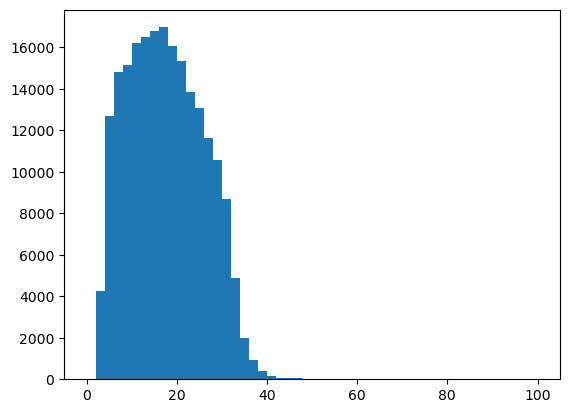

In [37]:
plt.hist(length_e, bins=50, range=(0,100))

In [10]:
total_labels_count = y_main.sum(axis=0)
total_labels_count

array([17131,  9245,  8084, 13618, 17620,  5999,  7359,  9692,  3817,
        8469, 11424,  5301,  2476,  5629,  3197, 11625,   673,  7983,
        8191,  1810,  8715,  1302,  8785,  1289,  2525,  6758,  5514,
       55298])

(array([17131.,  9245.,  8084., 13618., 17620.,  5999.,  7359.,  9692.,
         3817.,  8469., 11424.,  5301.,  2476.,  5629.,  3197., 11625.,
          673.,  7983.,  8191.,  1810.,  8715.,  1302.,  8785.,  1289.,
         2525.,  6758.,  5514., 55298.]),
 array([ 0.        ,  0.96428571,  1.92857143,  2.89285714,  3.85714286,
         4.82142857,  5.78571429,  6.75      ,  7.71428571,  8.67857143,
         9.64285714, 10.60714286, 11.57142857, 12.53571429, 13.5       ,
        14.46428571, 15.42857143, 16.39285714, 17.35714286, 18.32142857,
        19.28571429, 20.25      , 21.21428571, 22.17857143, 23.14285714,
        24.10714286, 25.07142857, 26.03571429, 27.        ]),
 <BarContainer object of 28 artists>)

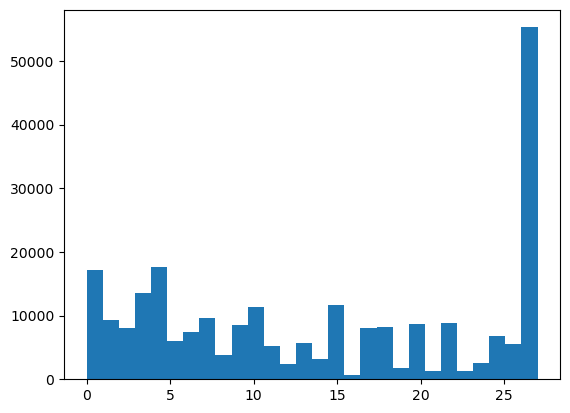

In [11]:
plt.hist(range(total_labels_count.shape[-1]), bins=28, weights=total_labels_count)

In [12]:
label_weights = total_labels_count.max() / total_labels_count
label_weights

array([ 3.22794933,  5.98139535,  6.84042553,  4.06065502,  3.13836549,
        9.21786964,  7.51433619,  5.70553033, 14.48729369,  6.52946038,
        4.8405112 , 10.43161668, 22.33360258,  9.82376976, 17.29684079,
        4.7568172 , 82.16641902,  6.92696981,  6.75106825, 30.55138122,
        6.34515204, 42.47158218,  6.29459306, 42.89992242, 21.90019802,
        8.1825984 , 10.02865433,  1.        ])

In [13]:
class_weights = dict(enumerate(label_weights))
class_weights

{0: np.float64(3.227949331621038),
 1: np.float64(5.981395348837209),
 2: np.float64(6.840425531914893),
 3: np.float64(4.060655015420767),
 4: np.float64(3.138365493757094),
 5: np.float64(9.217869644940823),
 6: np.float64(7.514336186981927),
 7: np.float64(5.705530334296327),
 8: np.float64(14.487293686140948),
 9: np.float64(6.529460384933286),
 10: np.float64(4.840511204481793),
 11: np.float64(10.43161667609885),
 12: np.float64(22.333602584814216),
 13: np.float64(9.823769763723574),
 14: np.float64(17.296840788238974),
 15: np.float64(4.7568172043010755),
 16: np.float64(82.16641901931649),
 17: np.float64(6.926969810848052),
 18: np.float64(6.751068245635453),
 19: np.float64(30.551381215469615),
 20: np.float64(6.345152036718302),
 21: np.float64(42.4715821812596),
 22: np.float64(6.294593056346044),
 23: np.float64(42.89992242048099),
 24: np.float64(21.90019801980198),
 25: np.float64(8.182598401894051),
 26: np.float64(10.028654334421473),
 27: np.float64(1.0)}

In [14]:
X_train_main, X_test_main, y_train_main, y_test_main = sklearn.model_selection.train_test_split(X_main, y_main, test_size=0.2, random_state=42, shuffle=True)

In [15]:
class Dataset(keras.utils.PyDataset):

    def __init__(
            self,
            X: list[list[int]],
            y: list[list[int]],
            batch_size: int,
            fixed_length: int | None = None,
            seed: int | None = None, 
            shuffle: bool = False, 
            **kwargs
    ):
        super().__init__(**kwargs)
        self.shuffle = shuffle
        self.batch_size = batch_size
        self.seed = seed
        self.rng = np.random.default_rng(seed)

        self.X = X
        self.y = y

        self.fixed_length = fixed_length if fixed_length else None

        self.image_index = np.arange(len(self.X))

        self.on_epoch_end()

    def __len__(self):
        return (len(self.X) + self.batch_size - 1) // self.batch_size

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.image_index)
    
    def __getitem__(self, index: int):
        start = index * self.batch_size
        end = (index + 1) * self.batch_size
        batch = self.image_index[start:end]

        _X = [self.X[idx] for idx in batch]

        batch_lenth = self.fixed_length

        if batch_lenth is None:
            batch_lenth = int(np.quantile([len(seq) for seq in _X], 0.8))
            add_noise = self.rng.integers(-batch_lenth // 2, batch_lenth // 2, endpoint=True)
            batch_lenth += add_noise

        _X = keras.utils.pad_sequences(_X, maxlen=batch_lenth, padding='post', truncating='post', value=tokenizer.eos_token_id)

        return _X, self.y[batch]


In [16]:
BATCH_SIZE = 1024

In [17]:
train_fixed = Dataset(X_train_main, y_train_main, batch_size=BATCH_SIZE, fixed_length=32, seed=42, shuffle=True)
test_fixed =  Dataset(X_test_main, y_test_main, batch_size=BATCH_SIZE, fixed_length=32, seed=42, shuffle=False)

In [18]:
train_variable = Dataset(X_train_main, y_train_main, batch_size=BATCH_SIZE, fixed_length=None, seed=42, shuffle=True)
test_variable = Dataset(X_test_main, y_test_main, batch_size=BATCH_SIZE, fixed_length=None, seed=42, shuffle=False)

In [84]:
for i in range(10):
    print(train_variable[i][0].shape)

(1024, 16)
(1024, 30)
(1024, 28)
(1024, 20)
(1024, 20)
(1024, 14)
(1024, 31)
(1024, 16)
(1024, 19)
(1024, 35)


# Model

Implement your model. The model should have the RNN architecture (with LSTM or GRU cells), support stacking and bidirectional feature extraction.

In [19]:
def get_name(prefix: str | None = None, suffix: str | None = None, separator: str = '_') -> str | None:
    return prefix and prefix + separator + suffix or suffix or None

In [20]:
def get_model(
    units: int,
    n_tokens: int,
    n_labels: int,
    n_stacks: int = 1,
    bidirectional: bool = False,
    name: str | None = None,
    # cell_type: type[keras.layers.Layer] = keras.layers.LSTMCell,
    cell_type: type[keras.layers.LSTMCell] | type[keras.layers.GRUCell] = keras.layers.LSTMCell,
) -> keras.Model:
    '''Creates a model with RNN architecture for sequence multilabel classification.

    Arguments:
        units: dimensionality of RNN cells
        n_tokens: number of tokens in the tokenizer dictionary
        n_labels: number of labels to be predicted
        n_stacks: number of RNN cells in the stack (1 -- no stacking)
        bidirectional: whether or not the model is bidirectional
        name: the model name
        cell_type: type of a cell to use, either keras.layers.LSTMCell or keras.layers.GRUCell

    Returns:
        The model'''

    inputs = x = keras.layers.Input((None,), dtype='int32', name='input')
    x = keras.layers.Embedding(n_tokens, units, name='embedding')(x)

    cells = [cell_type(units) for _ in range(n_stacks)]
    stacked_cells = keras.layers.StackedRNNCells(cells)
    rnn = keras.layers.RNN(
        stacked_cells,
        return_sequences=False,
        name="rnn_cell",
    )

    if bidirectional:
        rnn = keras.layers.Bidirectional(rnn, name=f"bidirectional")

    x = rnn(x)

    x = keras.layers.Dropout(0.2, name="dropout")(x)
    x = keras.layers.Dense(n_labels, activation='sigmoid', name='output')(x)
    return keras.models.Model(
        inputs=inputs, 
        outputs=x, 
        name=name
    )

In [21]:
# model_test = get_model(
#         units=32,
#         n_tokens=len(tokenizer.get_vocab()),
#         n_labels=len(emotions),
#         name="TEST",
#         bidirectional=False,
#         n_stacks=1,
#         cell_type=keras.layers.LSTMCell
#     )

# model_test.summary()

# Training

Train several models on the two dataset variants. Use either of the cell types (LSTM or GRU)
* Simple RNN (no stacking, one direction)
* Stacked RNN (stacking, one direction)
* Bidirectional RNN (no stacking, bidirectional)
* Stacked Bidirectional RNN (stacking, bidirectional)

In [22]:
ModelConfig = collections.namedtuple("ModelConfig", ["fixed", "units", "bidirectional", "stacks", "cell_type"])

In [23]:
model_configs = [
    ModelConfig(*c) 
    for c in itertools.product(
        [True, False],
        [128],
        [False, True],
        [1, 2],
        [keras.layers.LSTMCell],
    )
]
model_configs

[ModelConfig(fixed=True, units=128, bidirectional=False, stacks=1, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=True, units=128, bidirectional=False, stacks=2, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=True, units=128, bidirectional=True, stacks=1, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=True, units=128, bidirectional=True, stacks=2, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=False, units=128, bidirectional=False, stacks=1, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=False, units=128, bidirectional=False, stacks=2, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=False, units=128, bidirectional=True, stacks=1, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>),
 ModelConfig(fixed=False, units=128, bidirectional=True, stacks=2, cell_type=<class 'keras.src.layers.rnn.lstm.LSTMCell'>)]

In [27]:
def get_model_name(config: ModelConfig):
    return f"{config.cell_type.__name__}-{config.units} x {config.stacks} {'B ' if config.bidirectional else ''}{'F' if config.fixed else 'V'}"

In [196]:
models = [
    get_model(
        units=config.units,
        n_tokens=len(tokenizer.get_vocab()),
        n_labels=len(emotions),
        name=get_model_name(config),
        bidirectional=config.bidirectional,
        n_stacks=config.stacks,
        cell_type=config.cell_type
    )
    for config in model_configs
]

In [198]:
models

[<Functional name=LSTMCell-128 x 1 F, built=True>,
 <Functional name=LSTMCell-128 x 2 F, built=True>,
 <Functional name=LSTMCell-128 x 1 B F, built=True>,
 <Functional name=LSTMCell-128 x 2 B F, built=True>,
 <Functional name=LSTMCell-128 x 1 V, built=True>,
 <Functional name=LSTMCell-128 x 2 V, built=True>,
 <Functional name=LSTMCell-128 x 1 B V, built=True>,
 <Functional name=LSTMCell-128 x 2 B V, built=True>]

In [199]:
models[7].summary()

Model: "LSTMCell-128 x 2 B V"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, None, 128)      │     6,432,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       526,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 28)             │         7,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,966,428 (26.57 MB)

 Trainable params: 6,966,428 (26.57 MB)

 Non-trainable params: 0 (0.00 B)

Which loss should be used to multilabel classification? Which metrics?

In [25]:
SAVE_MODEL_PATH = Path("./saved")

In [201]:
for model in models:
    model.compile(
        loss=keras.losses.BinaryCrossentropy(from_logits=False),
        optimizer=keras.optimizers.Adam(),
        metrics=[
            keras.metrics.BinaryAccuracy(),
            keras.metrics.AUC(multi_label=True, num_labels=len(emotions)),
            keras.metrics.F1Score(average="macro"),
        ]
        # jit_compile=False
    )

In [202]:
for model in models[:4]:
    print()
    print(model.name)
    
    model.fit(
        train_fixed,
        validation_data=test_fixed,
        epochs=10,
        callbacks=[
            keras.callbacks.ModelCheckpoint(
                SAVE_MODEL_PATH / f"{model.name}.keras"
            )
        ],
        class_weight=class_weights
    )


LSTMCell-128 x 1 F
Epoch 1/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 21s 128ms/step - auc_8: 0.5001 - binary_accuracy: 0.9512 - f1_score: 0.0340 - loss: 1.1929 - val_auc_8: 0.5014 - val_binary_accuracy: 0.9579 - val_f1_score: 0.0046 - val_loss: 0.1722
Epoch 2/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 23s 141ms/step - auc_8: 0.4999 - binary_accuracy: 0.9578 - f1_score: 0.0345 - loss: 1.0086 - val_auc_8: 0.5012 - val_binary_accuracy: 0.9579 - val_f1_score: 0.0039 - val_loss: 0.1718
Epoch 3/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 21s 127ms/step - auc_8: 0.4999 - binary_accuracy: 0.9578 - f1_score: 0.0340 - loss: 1.0047 - val_auc_8: 0.5021 - val_binary_accuracy: 0.9579 - val_f1_score: 0.0021 - val_loss: 0.1717
Epoch 4/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 19s 117ms/step - auc_8: 0.5016 - binary_accuracy: 0.9578 - f1_score: 0.0336 - loss: 1.0023 - val_auc_8: 0.5016 - val_binary_accuracy: 0.9579 - val_f1_score: 0.0021 - val_loss: 0.1723
Epoch 5/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 19s 117ms/step - auc_8: 0.4995 - binary_accuracy

In [208]:
for model in models[4:]:
    print()
    print(model.name)
    
    model.fit(
        train_variable,
        validation_data=test_variable,
        epochs=10,
        callbacks=[
            keras.callbacks.ModelCheckpoint(
                SAVE_MODEL_PATH / f"{model.name}.keras"
            )
        ],
        class_weight=class_weights
    )


LSTMCell-128 x 1 V
Epoch 1/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 18s 109ms/step - auc_12: 0.7660 - binary_accuracy: 0.9582 - f1_score: 0.1473 - loss: 0.8517 - val_auc_12: 0.7677 - val_binary_accuracy: 0.9589 - val_f1_score: 0.1507 - val_loss: 0.1498
Epoch 2/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - auc_12: 0.7932 - binary_accuracy: 0.9590 - f1_score: 0.1974 - loss: 0.8072 - val_auc_12: 0.7806 - val_binary_accuracy: 0.9594 - val_f1_score: 0.2042 - val_loss: 0.1455
Epoch 3/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 17s 105ms/step - auc_12: 0.8141 - binary_accuracy: 0.9593 - f1_score: 0.2323 - loss: 0.7681 - val_auc_12: 0.7913 - val_binary_accuracy: 0.9593 - val_f1_score: 0.2268 - val_loss: 0.1414
Epoch 4/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 17s 103ms/step - auc_12: 0.8297 - binary_accuracy: 0.9592 - f1_score: 0.2652 - loss: 0.7323 - val_auc_12: 0.7932 - val_binary_accuracy: 0.9590 - val_f1_score: 0.2358 - val_loss: 0.1415
Epoch 5/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 17s 102ms/step - auc_12: 0.8390 - binary

In [28]:
models = [
    keras.models.load_model(
        SAVE_MODEL_PATH / f"{get_model_name(config)}.keras"
    )
    for config in model_configs
]
models

[<Functional name=LSTMCell-128 x 1 F, built=True>,
 <Functional name=LSTMCell-128 x 2 F, built=True>,
 <Functional name=LSTMCell-128 x 1 B F, built=True>,
 <Functional name=LSTMCell-128 x 2 B F, built=True>,
 <Functional name=LSTMCell-128 x 1 V, built=True>,
 <Functional name=LSTMCell-128 x 2 V, built=True>,
 <Functional name=LSTMCell-128 x 1 B V, built=True>,
 <Functional name=LSTMCell-128 x 2 B V, built=True>]

# Evaluation

Evaluate the models you trained on the test datasets. Plot ROC curves for each label (use `sklearn.metrics.RocCurveDisplay`) for each model.

In [35]:
def plot_roc_curve(
    X: np.ndarray,
    y: np.ndarray,
    model: keras.Model,
    ax: plt.Axes | None = None,
    is_legend: bool = False,
    batch_size: int = BATCH_SIZE,
) -> float:
    '''Plots ROC curves for each of the labels (on a single axes) and outputs mean ROC AUC score.

    Arguments:
        X: model inputs
        y: ground thruths
        model: model to plot the curve for
        ax: axes to plot on

    Returns:
        Mean ROC AUC score'''

    if ax is None:
        ax = plt.gca()

    y_pred = model.predict(X, batch_size=batch_size)

    # aucs = []
    for i in range(y.shape[-1]):
        disp = sklearn.metrics.RocCurveDisplay.from_predictions(
            y[:, i], 
            y_pred[:, i], 
            name=f"Class {i}",
            ax=ax
        )
        # aucs.append(disp.roc_auc)

    ax.plot([0, 1], [0, 1], "k--")
    ax.grid(True)
    # mean_auc = np.mean(aucs)
    mean_auc = sklearn.metrics.roc_auc_score(y, y_pred)

    if not is_legend:
        ax.get_legend().remove()

    ax.set_title(f"ROC AUC: {mean_auc:.3f}")

    return mean_auc

42/42 ━━━━━━━━━━━━━━━━━━━━ 6s 149ms/step


0.7515235350383885

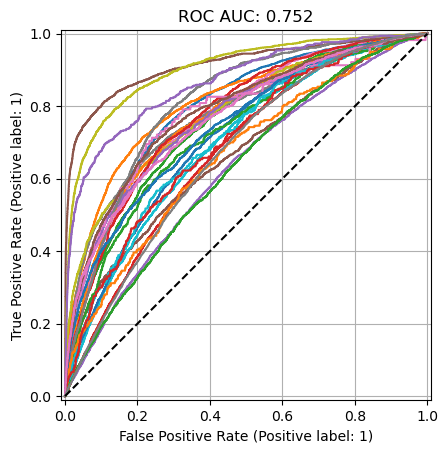

In [211]:
plot_roc_curve(test_variable, test_fixed.y, models_[7])

Plot the mean ROC AUC scores. Which model has the highest score? On what kind of dataset?

42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 102ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 8s 182ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 6s 151ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 96ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 8s 180ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 6s 152ms/step


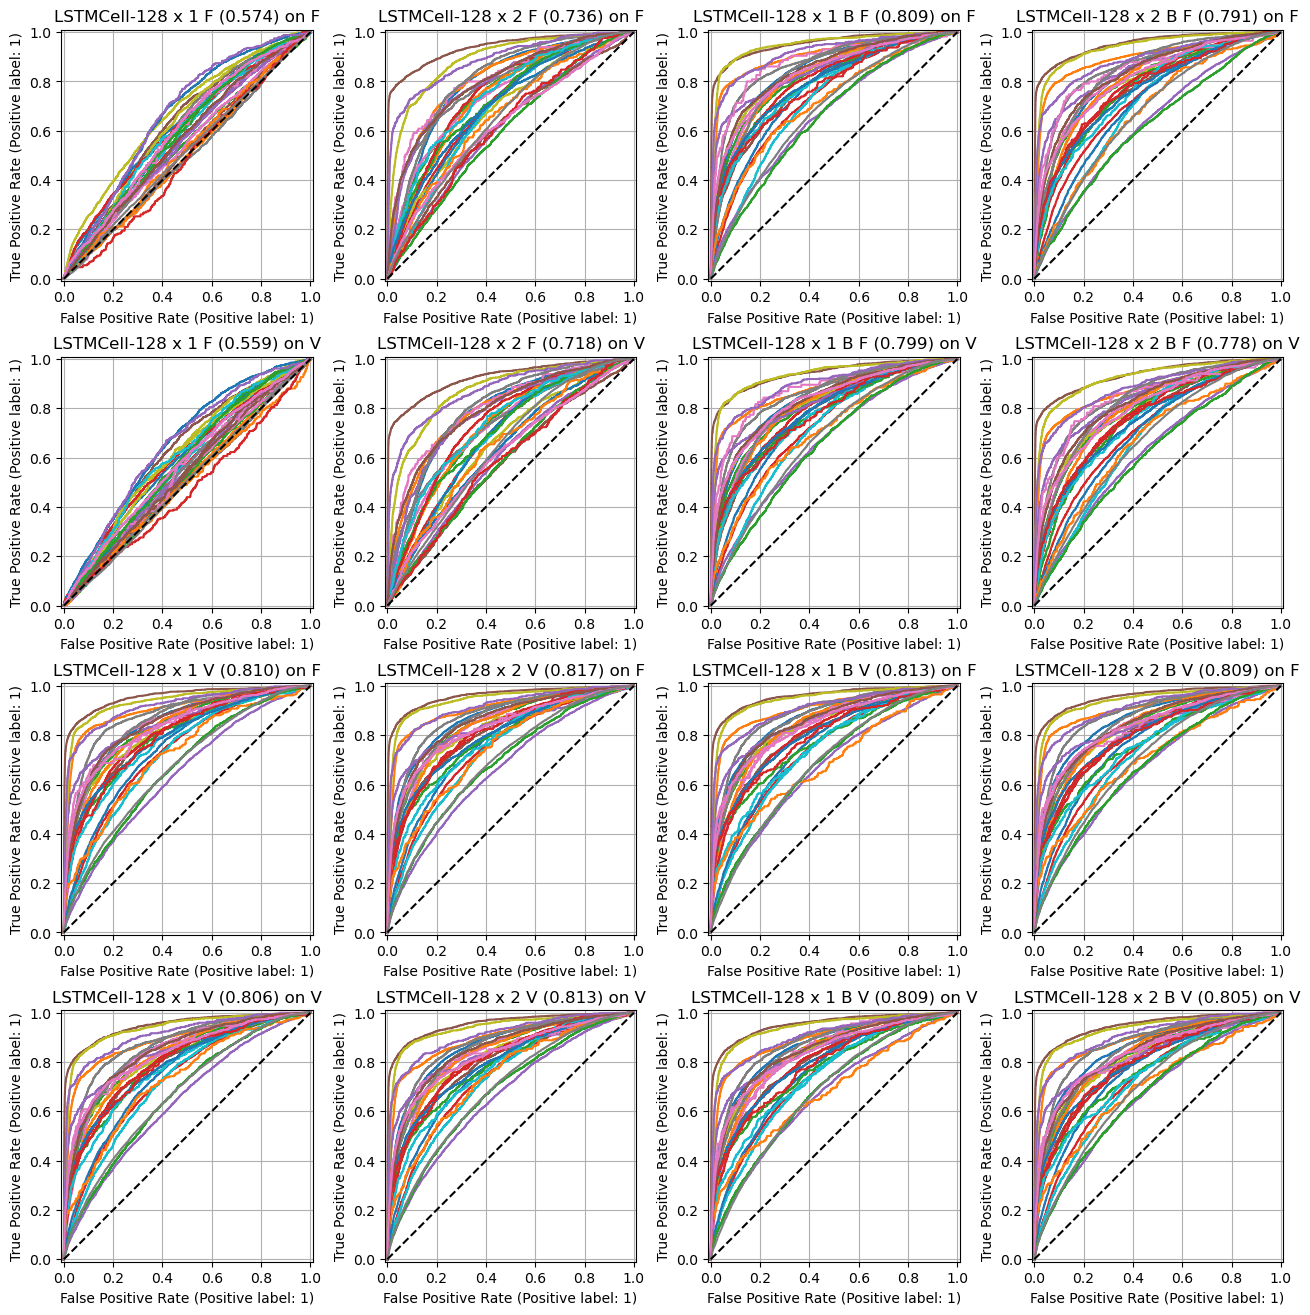

In [212]:
fig, axs = plt.subplots(4, 4, figsize=(16, 16))

for i, model in enumerate(models):
    row = i // 4
    col = i % 4
    ax1 = axs[2 * row, col]
    roc_auc = plot_roc_curve(test_fixed, test_fixed.y, model, ax=ax1)
    ax1.set_title(f"{model.name} ({roc_auc:.3f}) on F")
    
    ax2 = axs[2 * row + 1, col]
    roc_auc = plot_roc_curve(test_variable, test_variable.y, model, ax=ax2)
    ax2.set_title(f"{model.name} ({roc_auc:.3f}) on V")

plt.subplots_adjust(hspace=0.3)

Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [36]:
def label_text(text: str, model: keras.Model, threshold: float = 0.5, max_length: int | None = None) -> list[str]:
    '''Computes the model output for `text` and outputs a list of emotions that have a probability of at least `threshold`

    Arguments:
        text: text to label
        model: model to use
        threshold: threshold to use
        max_length: max length for tokenization
    
    Return:
        List of predicted emotion labels'''

    tokens = np.array([tokenizer.encode(text, max_length=max_length)])
    y_pred = model.predict(tokens, verbose=0)[0] > threshold
    return [e for e, y in zip(emotions, y_pred) if y]

In [37]:
def plot_emotion_scores(text: str, model: keras.Model, max_length: int | None = None, ax: plt.Axes | None = None):
    '''Plots a bar plot of emotion probabilities for given `text` using `model`.

    Arguments:
        text: text to label
        model: model to use        
        max_length: max length for tokenization
        ax: axes to plot on'''

    if ax is None:
        ax = plt.gca()

    tokens = np.array([tokenizer.encode(text, max_length=max_length)])
    y_pred = model.predict(tokens, verbose=0)[0]

    ax.bar(emotions, y_pred)
    ax.set_xticks(range(len(emotions)))
    ax.set_xticklabels(emotions, rotation=90)
    ax.grid(True)

For each of your texts get a list of emotion labels and plot emotion scores

In [38]:
some_texts = [
    "aahsdljhlj lj kjhlkahs",
    "Aasdkljf? uoifupoiur! 09090--!!",
    "ылдважопждлывоалдожш мымшоуы шош",
    
    "23094!(*$809-434=-0_",
    'empty',
    'emtpyness',
    
    "I just came up with simple yet exciting solution to this question",
    "I just came up with simple yet exciting solution to this question!",
    "I just came up with simple yet exciting solution to this question?",
    
    'I want to get this chocolate',
    "How are you doing here?",
    "I hate that nothing is working out",
    
    "Spiders are scary for those with arachnafobia",
    "yo dudes! this chad is sigma!!! 67",
    "You can watch some tutorials on YouTube",
    
    "Greetings, my dear King!",
    "Greetings, my friend!",
    "Greetings, my lovely lady!",
    
    'Have you seen John in the last five or so days?',
    'Have you seen John in the last five or so days? I am worried about him',
    'Have you seen John in the last five or so days? He should\'ve finished with that damn project already!',
    
    "wow, this is so uninteresting...",
    "this is so uninteresting...",
    "THIS IS SOOOO UNINTERESTINGGG!!!",

    "This is a neutral sentence",
    "OH MY GOD!",
    'The quick brown fox jumps over the lazy dog',
]

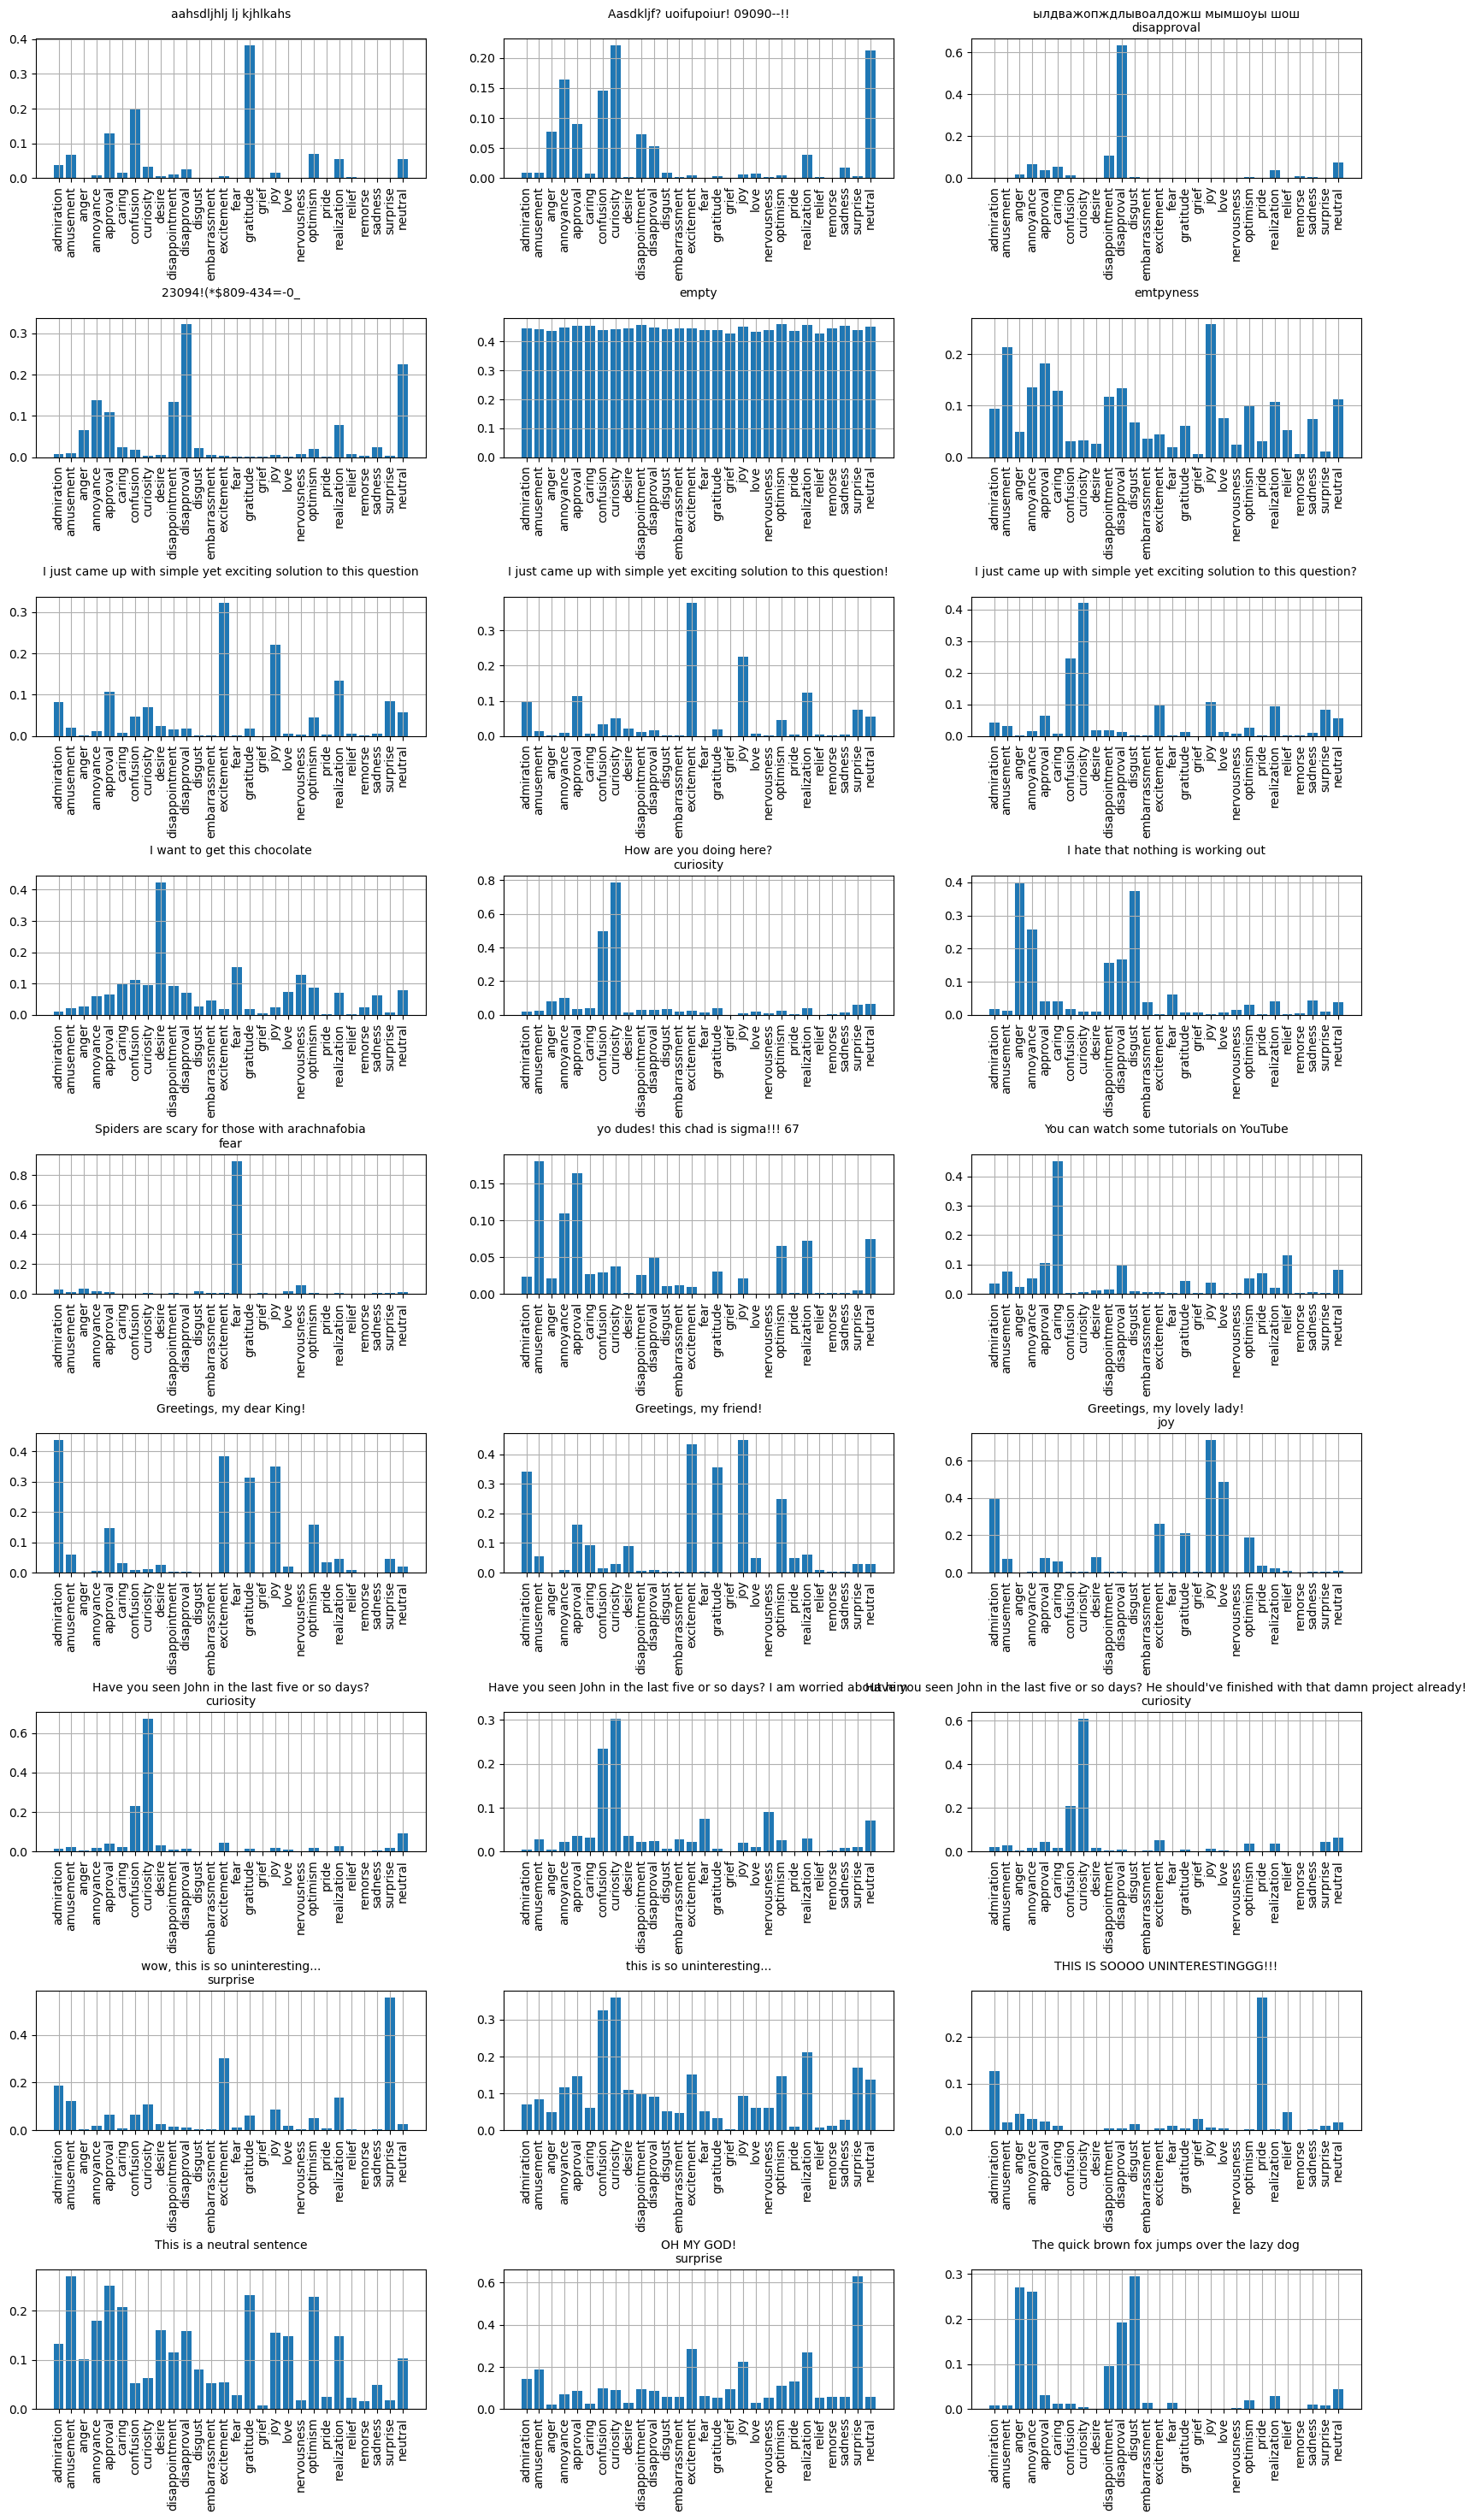

In [320]:
rows, cols = 9, 3

t_fig, t_axs = plt.subplots(rows, cols, figsize=(20, rows * 4))

selected_model = models[7]

for i, t in enumerate(some_texts):
    row = i // cols
    col = i % cols

    labels = label_text(t, selected_model)

    ax = t_axs[row, col]
    plot_emotion_scores(t, models[7], ax=ax)
    ax.set_title(f"{t}\n{', '.join(labels)}", fontsize=10)
    
plt.subplots_adjust(hspace=1)

# Bonus

Train and evaluate the same model as your best one, but use a different cell type

In [30]:
model_configs2 = [
    ModelConfig(*c) 
    for c in itertools.product(
        [False],
        [128],
        [False, True],
        [2],
        [keras.layers.GRUCell],
    )
]
model_configs2

[ModelConfig(fixed=False, units=128, bidirectional=False, stacks=2, cell_type=<class 'keras.src.layers.rnn.gru.GRUCell'>),
 ModelConfig(fixed=False, units=128, bidirectional=True, stacks=2, cell_type=<class 'keras.src.layers.rnn.gru.GRUCell'>)]

In [31]:
models2 = [
    get_model(
        units=config.units,
        n_tokens=len(tokenizer.get_vocab()),
        n_labels=len(emotions),
        name=get_model_name(config),
        bidirectional=config.bidirectional,
        n_stacks=config.stacks,
        cell_type=config.cell_type
    )
    for config in model_configs2
]
models2

[<Functional name=GRUCell-128 x 2 V, built=True>,
 <Functional name=GRUCell-128 x 2 B V, built=True>]

In [32]:
for model in models2:
    model.compile(
        loss=keras.losses.BinaryCrossentropy(from_logits=False),
        optimizer=keras.optimizers.Adam(),
        metrics=[
            keras.metrics.BinaryAccuracy(),
            keras.metrics.AUC(multi_label=True, num_labels=len(emotions)),
            keras.metrics.F1Score(average="macro"),
        ]
    )

In [33]:
for model in models2:
    print()
    print(model.name)
    
    model.fit(
        train_variable,
        validation_data=test_variable,
        epochs=10,
        callbacks=[
            keras.callbacks.ModelCheckpoint(
                SAVE_MODEL_PATH / f"{model.name}.keras"
            )
        ],
        class_weight=class_weights
    )


GRUCell-128 x 2 V
Epoch 1/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 24s 140ms/step - auc: 0.4994 - binary_accuracy: 0.9534 - f1_score: 0.0345 - loss: 1.2116 - val_auc: 0.5000 - val_binary_accuracy: 0.9579 - val_f1_score: 0.0037 - val_loss: 0.1726
Epoch 2/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 24s 142ms/step - auc: 0.4995 - binary_accuracy: 0.9578 - f1_score: 0.0355 - loss: 1.0303 - val_auc: 0.5010 - val_binary_accuracy: 0.9579 - val_f1_score: 0.0021 - val_loss: 0.1723
Epoch 3/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 23s 138ms/step - auc: 0.5034 - binary_accuracy: 0.9578 - f1_score: 0.0358 - loss: 1.0215 - val_auc: 0.5399 - val_binary_accuracy: 0.9579 - val_f1_score: 0.0157 - val_loss: 0.1722
Epoch 4/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 23s 137ms/step - auc: 0.5537 - binary_accuracy: 0.9579 - f1_score: 0.0547 - loss: 0.9926 - val_auc: 0.6368 - val_binary_accuracy: 0.9588 - val_f1_score: 0.0519 - val_loss: 0.1628
Epoch 5/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 23s 139ms/step - auc: 0.6359 - binary_accuracy: 0.9588 - f1_score

In [ ]:
models2 = [
    keras.models.load_model(
        SAVE_MODEL_PATH / f"{get_model_name(config)}.keras"
    )
    for config in model_configs2
]
models2

42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 7s 159ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 5s 112ms/step


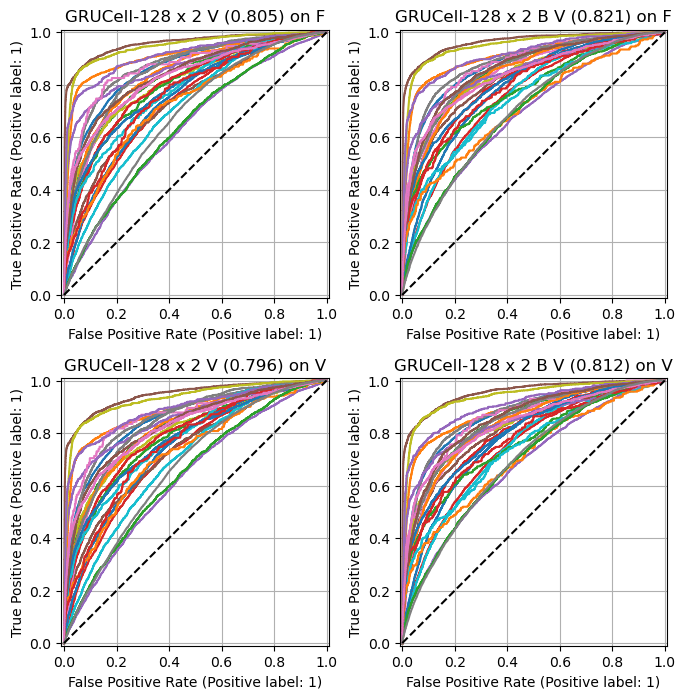

In [39]:
fig, axs = plt.subplots(2, 2, figsize=(8, 8))

for i, model in enumerate(models2):
    row = i // 4
    col = i % 4
    ax1 = axs[2 * row, col]
    roc_auc = plot_roc_curve(test_fixed, test_fixed.y, model, ax=ax1)
    ax1.set_title(f"{model.name} ({roc_auc:.3f}) on F")
    
    ax2 = axs[2 * row + 1, col]
    roc_auc = plot_roc_curve(test_variable, test_variable.y, model, ax=ax2)
    ax2.set_title(f"{model.name} ({roc_auc:.3f}) on V")

plt.subplots_adjust(hspace=0.3)

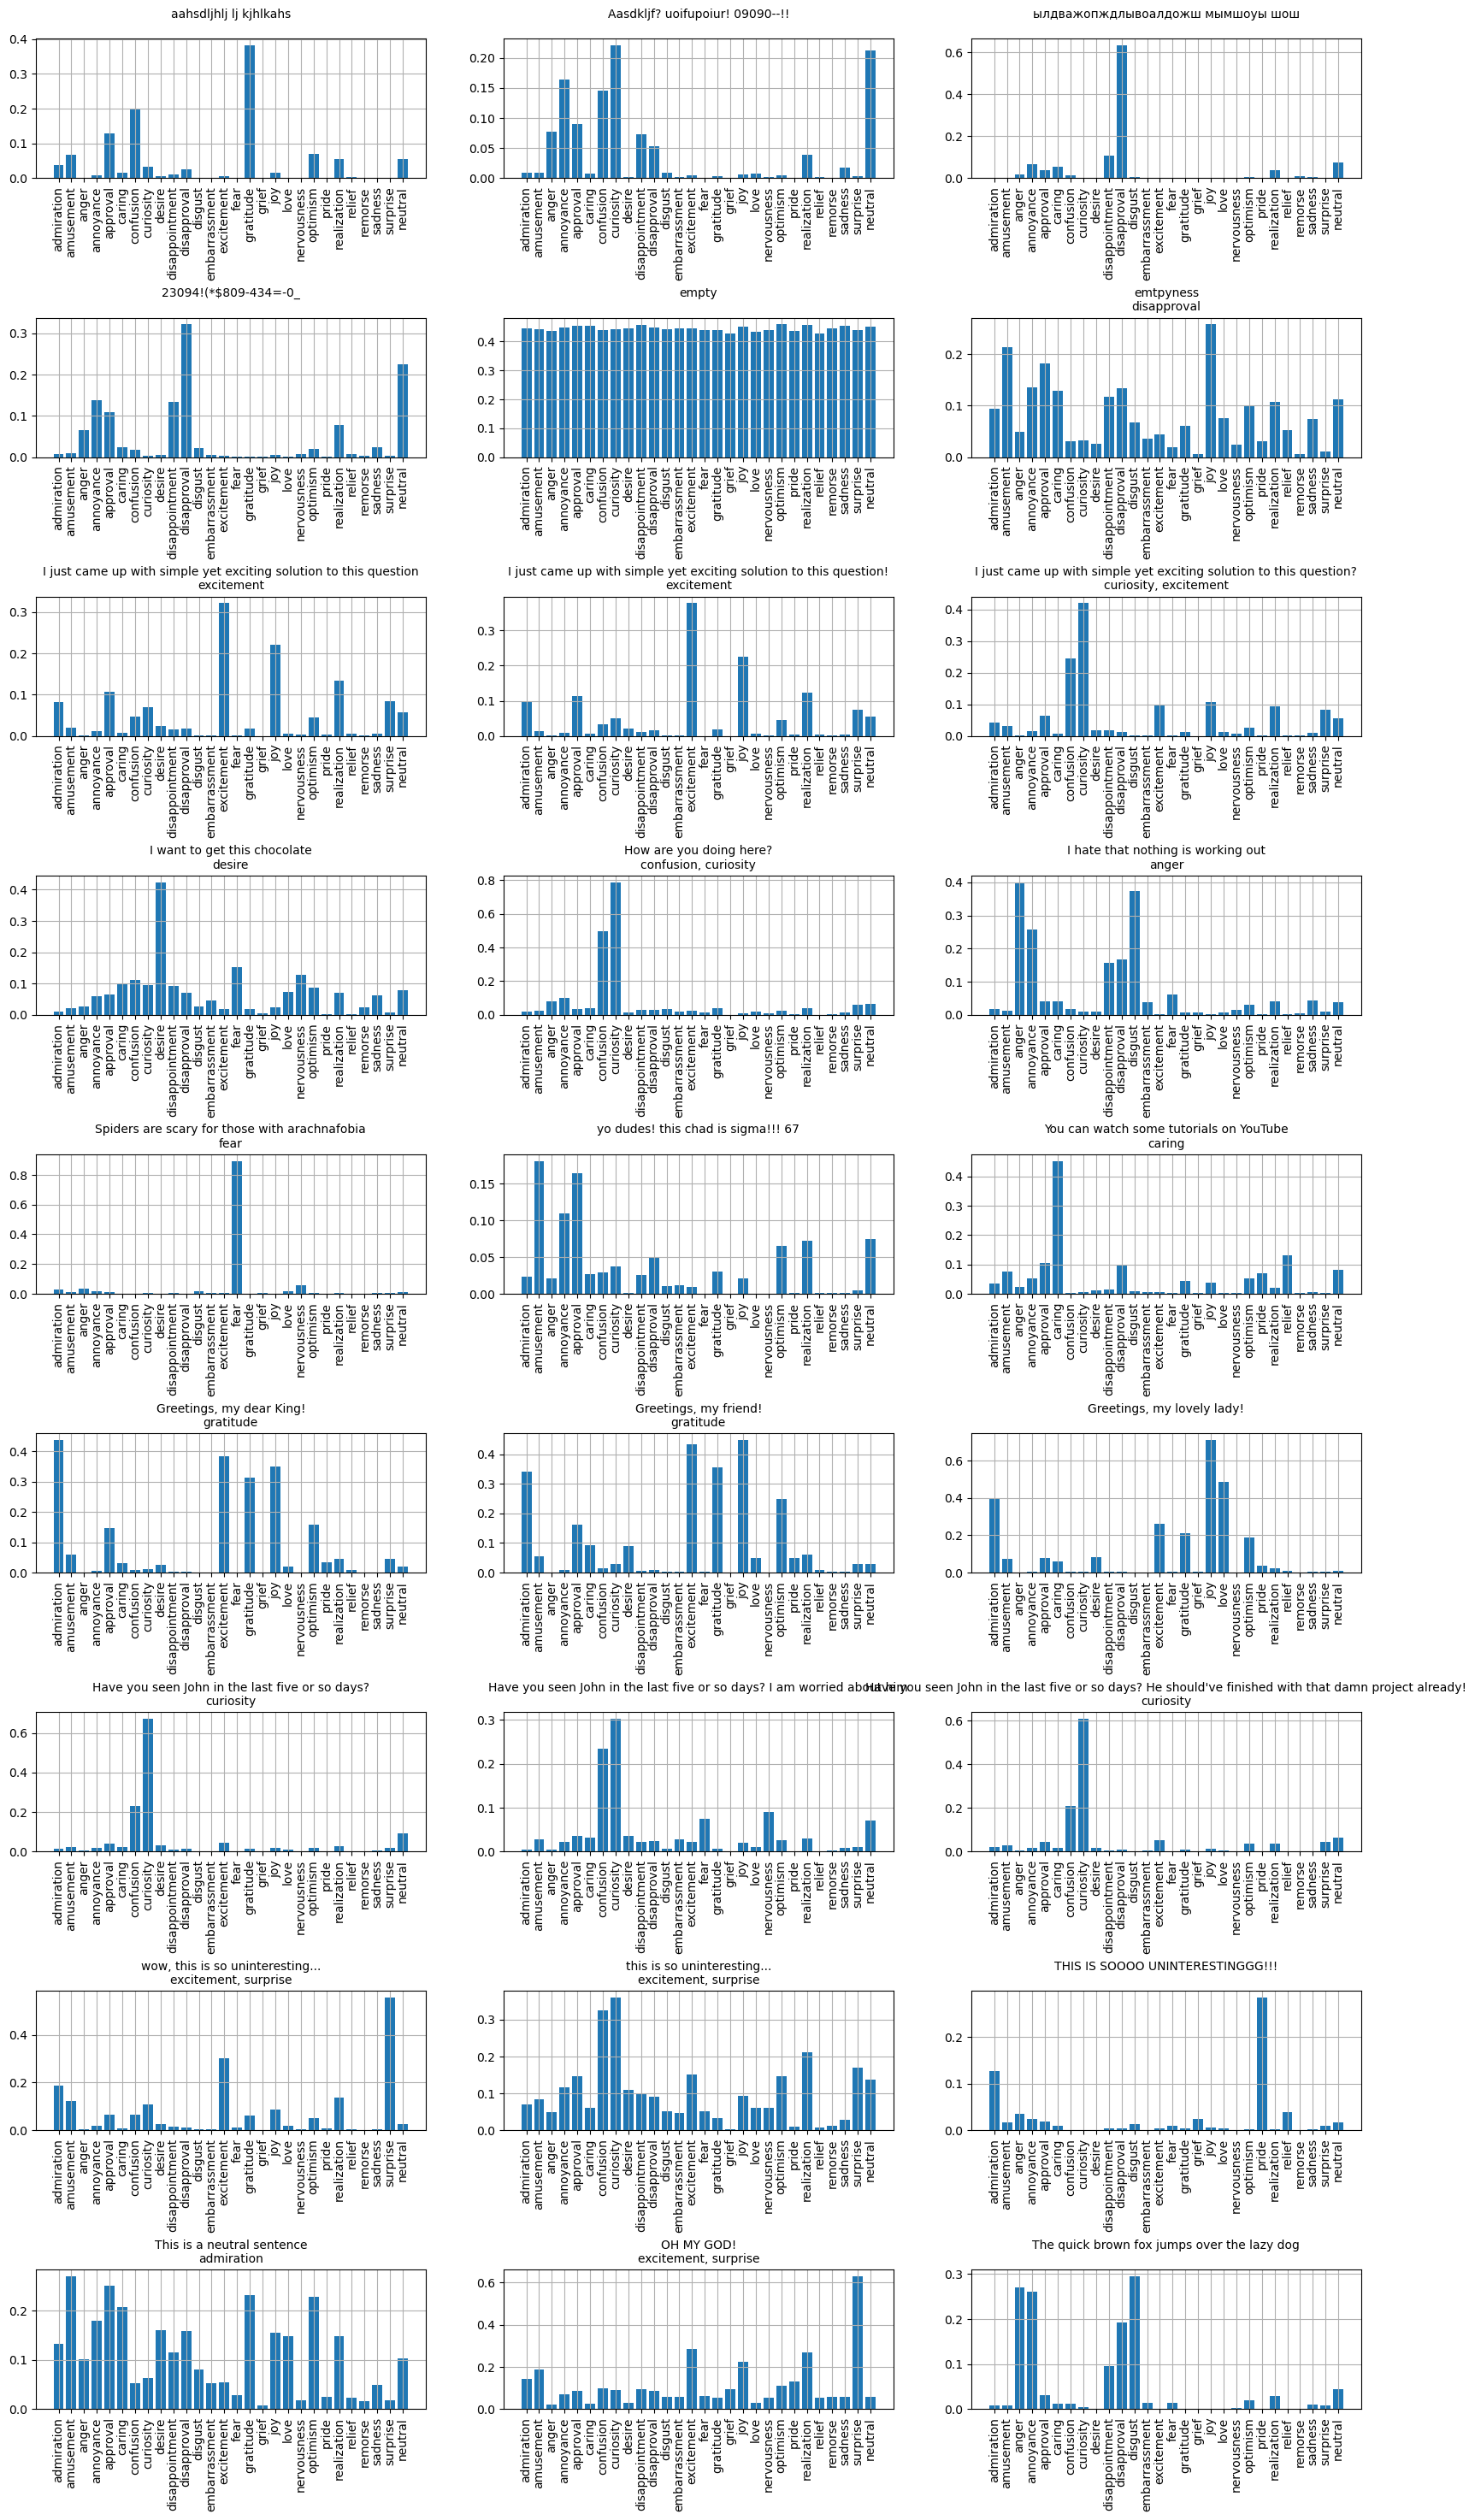

In [40]:
rows, cols = 9, 3

t_fig, t_axs = plt.subplots(rows, cols, figsize=(20, rows * 4))

selected_model = models2[1]

for i, t in enumerate(some_texts):
    row = i // cols
    col = i % cols

    labels = label_text(t, selected_model)

    ax = t_axs[row, col]
    plot_emotion_scores(t, models[7], ax=ax)
    ax.set_title(f"{t}\n{', '.join(labels)}", fontsize=10)
    
plt.subplots_adjust(hspace=1)